# Módulo 5 — Teoría y demostraciones

Notebook de apoyo para la teoría de los **Días 8 y 9** (ver
[`README.md`](../README.md)).

> **Nota sobre los datos usados:** todo este notebook usa datos **100%
> reales**, no sintéticos: la estación Ezeiza (Argentina, dentro del
> dominio real del WRF de muestra del Módulo 4), su observación horaria
> real decodificada de mensajes SYNOP (`data/obs/Ezeiza_2024_12_13_horario.csv`),
> el `wrfout` real de **día completo**
> (`data/grid_muestra/wrfout_muestra.nc`, 24 pasos horarios del
> 2024-12-13) y ERA5-Land real (`data/era_muestra/era5_land_20241213.nc`,
> también 24 horas). Con n=24 en un solo punto, estas cifras ya son una
> muestra razonable — la muestra multi-estación del entregable del módulo
> (n>100) sigue siendo la más robusta para conclusiones generales.

## Sección 1 — Tipos de datos observacionales (recordatorio breve)

Igual que se distinguió reanálisis vs. pronóstico operativo en el Módulo 3,
aquí interesa distinguir la naturaleza de la referencia usada para validar:

In [1]:
import pandas as pd

tipos = pd.DataFrame({
    "Naturaleza": ["Medición directa en un punto", "Medición indirecta (retrieval)", "Modelo + asimilación"],
    "Cobertura": ["Puntual, alta confiabilidad local", "Espacialmente extensa", "Espacialmente extensa"],
    "Advertencia": ["Ninguna estación vecina", "Incertidumbre del algoritmo, nubes", "CIRCULAR si el WRF fue forzado con la misma fuente"],
}, index=["Estación meteorológica", "Satélite", "Reanálisis (p.ej. ERA5)"])
tipos

,Naturaleza,Cobertura,Advertencia
Estación meteorológica,Medición directa en un punto,"Puntual, alta confiabilidad local",Ninguna estación vecina
Satélite,Medición indirecta (retrieval),Espacialmente extensa,"Incertidumbre del algoritmo, nubes"
Reanálisis (p.ej. ERA5),Modelo + asimilación,Espacialmente extensa,CIRCULAR si el WRF fue forzado con la misma fu...


## Sección 2 — Cargar observación real y WRF real en un punto (Ezeiza)

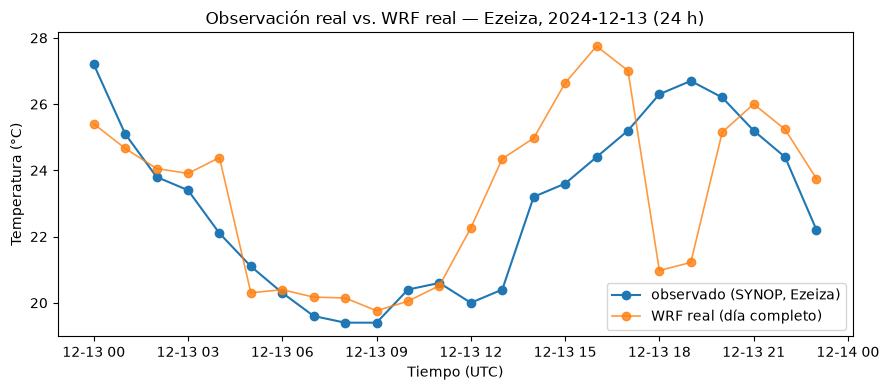

In [2]:
import json
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

coords = json.load(open("../../../data/ogimet/coords_area_wrf.json"))
c = coords["Ezeiza"]

# wrfout_muestra.nc: dia completo (24 pasos horarios), solo variables de
# superficie (T2/U10/V10/RAINC/RAINNC). No trae SINALPHA/COSALPHA, pero no
# hacen falta: el Modulo 4 ya establecio que en este dominio (proyeccion
# Mercator) el viento grid-relative y earth-relative son identicos (rotacion
# cero), asi que U10/V10 crudos se pueden usar directo. Tampoco hace falta
# xwrf: XLAT/XLONG/XTIME ya vienen listos para usar.
ds_wrf = xr.open_dataset("../../../data/grid_muestra/wrfout_muestra.nc")

def punto_mas_cercano(ds, lat, lon):
    dist2 = (ds["XLAT"] - lat) ** 2 + (ds["XLONG"] - lon) ** 2
    return np.unravel_index(np.argmin(dist2.values), dist2.shape)

iy, ix = punto_mas_cercano(ds_wrf, c["lat"], c["lon"])
tiempos = pd.to_datetime(ds_wrf["XTIME"].values)

obs_horaria = pd.read_csv("../../../data/obs/Ezeiza_2024_12_13_horario.csv",
                           parse_dates=["tiempo"]).set_index("tiempo")

obs = obs_horaria.reindex(tiempos)["temp_C"]
sim = pd.Series(
    (ds_wrf["T2"].isel(south_north=iy, west_east=ix) - 273.15).values,
    index=tiempos, name="T2_wrf",
)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(obs.index, obs.values, "o-", label="observado (SYNOP, Ezeiza)", linewidth=1.5)
ax.plot(sim.index, sim.values, "o-", label="WRF real (día completo)", linewidth=1.2, alpha=0.8)
ax.set_xlabel("Tiempo (UTC)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Observación real vs. WRF real — Ezeiza, 2024-12-13 (24 h)")
ax.legend()
fig.tight_layout()
plt.show()

## Sección 3 — Métricas de error: implementación y verificación de sus propiedades

**Glosario de símbolos** (el mismo usado en las diapositivas de teoría del
Día 8): `n` es el número de pares observado/simulado; `s` es el arreglo de
valores **s**imulados y `o` el de valores **o**bservados; `s̄`/`ō` (con
barra) son sus promedios; `σ` (sigma) es la desviación estándar, es decir,
cuánto varía cada serie respecto a su propio promedio. Las funciones de
abajo son la traducción directa a código de las fórmulas de la teoría.

In [3]:
def calcular_mae(s, o):
    # MAE = (1/n) * suma(|s_i - o_i|)  -- promedio del error en valor absoluto
    return float(np.mean(np.abs(s - o)))

def calcular_rmse(s, o):
    # RMSE = raiz[ (1/n) * suma((s_i - o_i)^2) ]  -- penaliza mas los errores grandes
    return float(np.sqrt(np.mean((s - o) ** 2)))

def calcular_bias(s, o):
    # bias = (1/n) * suma(s_i - o_i)  -- promedio de la diferencia, con signo
    return float(np.mean(s - o))

def calcular_r(s, o):
    # correlacion de Pearson: que tan bien sigue s el patron de o
    return float(np.corrcoef(s, o)[0, 1])

def calcular_kge(s, o):
    r = calcular_r(s, o)
    beta = np.mean(s) / np.mean(o)   # razon de sesgo relativo (s_promedio / o_promedio)
    alpha = np.std(s) / np.std(o)    # razon de variabilidad (sigma_s / sigma_o)
    kge = 1 - np.sqrt((r - 1) ** 2 + (beta - 1) ** 2 + (alpha - 1) ** 2)
    return kge, {"r": r, "beta": beta, "alpha": alpha}


mae = calcular_mae(sim.values, obs.values)
rmse = calcular_rmse(sim.values, obs.values)
bias = calcular_bias(sim.values, obs.values)
r_val = calcular_r(sim.values, obs.values)
kge_val, componentes = calcular_kge(sim.values, obs.values)

print(f"MAE  = {mae:.3f} °C")
print(f"RMSE = {rmse:.3f} °C")
print(f"bias = {bias:.3f} °C")
print(f"r    = {r_val:.3f}")
print(f"KGE  = {kge_val:.3f}  (componentes: {componentes})")
print()
print(f"¿RMSE >= MAE? -> {rmse >= mae} (siempre debe cumplirse)")

MAE  = 1.646 °C
RMSE = 2.250 °C
bias = 0.369 °C
r    = 0.606
KGE  = 0.606  (componentes: {'r': 0.605925090998234, 'beta': np.float64(1.0160999859692357), 'alpha': np.float64(1.0027594336766703)})

¿RMSE >= MAE? -> True (siempre debe cumplirse)


## Sección 4 (opcional) — Diagrama de Taylor: verificación de la ley de cosenos

> **Opcional.** Para quien quiera ver de dónde sale el diagrama. No hace
> falta para leerlo ni para la práctica: basta con saber que el mejor modelo
> es el punto más cercano a la observación.

$$\text{RMSE}_{centrado}^2 = \sigma_s^2 + \sigma_o^2 - 2\,\sigma_s\,\sigma_o\, r$$

Esta expresión tiene exactamente la misma forma que la ley de cosenos de
trigonometría básica, usada para hallar el lado de un triángulo:
$c^2 = a^2 + b^2 - 2ab\cos(\theta)$. La identificación es directa:
$a=\sigma_s$, $b=\sigma_o$, y $\cos(\theta)=r$ (es decir,
$\theta = \arccos(r)$, el ángulo con el que cada modelo se ubica en el
diagrama de Taylor). "RMSE centrado" es el RMSE calculado sobre las
anomalías (cada valor menos su propio promedio), no sobre los valores
crudos — por eso el sesgo queda fuera de esta identidad.

In [4]:
sigma_s = float(np.std(sim.values))
sigma_o = float(np.std(obs.values))

rmse_centrado_formula = np.sqrt(sigma_s**2 + sigma_o**2 - 2 * sigma_s * sigma_o * r_val)

anomalia_s = sim.values - sim.values.mean()
anomalia_o = obs.values - obs.values.mean()
rmse_centrado_directo = calcular_rmse(anomalia_s, anomalia_o)

print(f"RMSE centrado (fórmula, ley de cosenos): {rmse_centrado_formula:.4f}")
print(f"RMSE centrado (cálculo directo sobre anomalías): {rmse_centrado_directo:.4f}")
print(f"¿Coinciden? -> {np.isclose(rmse_centrado_formula, rmse_centrado_directo)}")

RMSE centrado (fórmula, ley de cosenos): 2.2199
RMSE centrado (cálculo directo sobre anomalías): 2.2199
¿Coinciden? -> True


## Sección 5 — Preview: valor añadido (added value)

**Definición general:** el valor añadido compara, contra un mismo dato
observado real (la referencia), dos fuentes de estimación en el mismo
punto: el **modelo global** (ERA5 o GFS) **interpolado** a esa ubicación, y
la **salida del WRF interpolada** a la misma ubicación. Acá usamos
ERA5-Land real en el mismo punto (Ezeiza) y las 24 horas del día — el
mismo dato real que se usa en el entregable del módulo, en preview.

In [5]:
era5 = xr.open_dataset("../../../data/era_muestra/era5_land_20241213.nc")

modelo_global = pd.Series(
    era5["t2m"].sel(latitude=c["lat"], longitude=c["lon"], method="nearest").values - 273.15,
    index=tiempos, name="t2m_era5",
)

rmse_wrf = calcular_rmse(sim.values, obs.values)
rmse_global = calcular_rmse(modelo_global.values, obs.values)
kge_wrf, _ = calcular_kge(sim.values, obs.values)
kge_global, _ = calcular_kge(modelo_global.values, obs.values)

resumen_av = pd.DataFrame({
    "RMSE": [rmse_wrf, rmse_global],
    "KGE": [kge_wrf, kge_global],
}, index=["WRF (real)", "Modelo global (ERA5-Land, real)"])
resumen_av

,RMSE,KGE
WRF (real),2.250359,0.605587
"Modelo global (ERA5-Land, real)",1.820004,0.669067


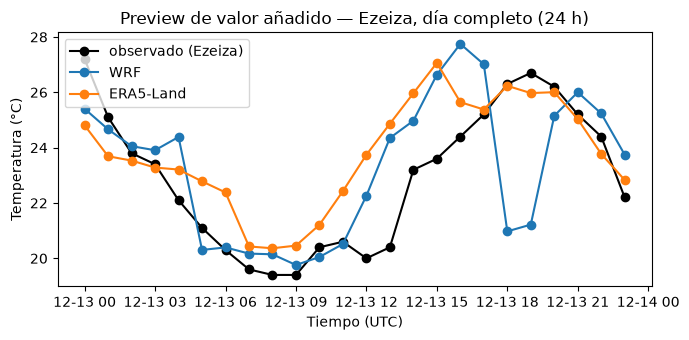

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(obs.index, obs.values, "ko-", label="observado (Ezeiza)")
ax.plot(sim.index, sim.values, "o-", label="WRF")
ax.plot(modelo_global.index, modelo_global.values, "o-", label="ERA5-Land")
ax.set_xlabel("Tiempo (UTC)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Preview de valor añadido — Ezeiza, día completo (24 h)")
ax.legend()
fig.tight_layout()
plt.show()

In [7]:
hay_valor_agregado = (rmse_wrf < rmse_global) and (kge_wrf > kge_global)
print(f"¿Hay evidencia de valor añadido del WRF frente al modelo global (en este punto, 24 h)? -> {hay_valor_agregado}")
print("Con n=24 en una sola estación, esto ya es informativo -- el entregable del módulo")
print("lo confirma (o no) con las 6 estaciones del dominio a la vez.")

¿Hay evidencia de valor añadido del WRF frente al modelo global (en este punto, 24 h)? -> False
Con n=24 en una sola estación, esto ya es informativo -- el entregable del módulo
lo confirma (o no) con las 6 estaciones del dominio a la vez.


---
Continuar con [`02_practica_dia8_metricas.ipynb`](02_practica_dia8_metricas.ipynb).